# Are the higher harmonics actually small? A direct check

**The question.** The two-timescale solution keeps only the mean and the first harmonic of the valve term in the pressure equation and drops $\cos 2\psi$, $\cos 3\psi$, … The valves clip and open abruptly, so their flow waveforms are far from sinusoidal — the dropped harmonics of the *flow* are not small at all. The claim being tested is narrower: the resonator's *pressure response* to those harmonics is small, and it never accumulates.

**What this notebook computes**, with your `V_passive_sweep_energy_balance.ipynb` constants and the family $V_{0,cv} = 10^{-4}$ m³ that runs as a steady oscillation:

- **A.** The Fourier coefficients of the valve term $\frac{C_f}{\bar V_{cv}}\left(T_{in}F_{in} - \bar T F_{out}\right)$ over one cycle, at the start of filling and on the steady oscillation. Written as $g_n\,\delta\cos n\psi$ so that $g_1 = g$ of the packet derivation; the $g_n$ for $n \ge 2$ turn out to be comparable to $g$.
- **B.** What the resonator does with each: the first harmonic sets the growth rate $\lambda = -b/2m + gL/2$ (per-cycle growth $2\pi\lambda/\omega_0$, compounding); the $n$-th harmonic produces a bounded ripple of relative size $\lvert\hat p_n\rvert/\delta = \dfrac{\lvert g_n\rvert}{n\,\omega_0}\left(1 + \dfrac{L}{n^2-1}\right)$, derived by projecting the fast equations onto $e^{-in\psi}$.
- **C.** The same numbers measured in the full simulation: the harmonic content of the simulated flows (large) and of the simulated pressure oscillation (small), during growth and on the steady oscillation, compared with the prediction of B. This turns up one thing worth knowing: the largest $\cos 2\psi$ in the pressure trace (about 2.5 percent of $\delta$) does not come from the valves at all but from the curvature of the gas spring — the adiabat $PV^{\gamma}$ that the packet derivation linearizes in [10] — and it too is a bounded ripple, proportional to $\delta^2/\bar P$. A sealed run with the valves shut confirms it.
- **D.** The fast system driven by the first harmonic alone versus the second harmonic alone, at equal strength.

Runtime: under a minute.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import butter, filtfilt

# ---- constants: identical to V_passive_sweep_energy_balance.ipynb ----
gamma = 1.41
R = 287.0
cp, cv = 1050.0, 744.0
P_in, P_out, P0 = 6e5, 5.45e5, 5.75e5
T_in = 300.0; T0 = T_in
A_neck = 2.85e-4
m_gas = 0.0015
b_gas = 0.005
zeta = 0.6
dP_max = (P_in - P_out) / (2 * zeta)
m_max = 0.001
x0, v0 = 0.0, 5.0
V0_pass = 2e-4
V0_cv = 1e-4                      # the family that runs as a steady oscillation
gamma_E = 1.0 + R / cv
Cf = cp * R / cv

BLUE, ORANGE, AQUA, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e8e7e3'

def reed_flow_vec(dP):
    dP = np.asarray(dP, dtype=float)
    u = dP / dP_max
    out = np.zeros_like(dP)
    mo = (dP > 0) & (dP < dP_max)
    mr = dP <= 0
    out[mo] = m_max * (1 - u[mo]) * np.sqrt(u[mo])
    out[mr] = -m_max * (1 - u[mr]) * np.sqrt(np.abs(u[mr]))
    return out

def reed_flow(dP):
    return float(reed_flow_vec(np.array([dP]))[0])

def geom(Pb):
    Vp = V0_pass * (P0 / Pb)**(1.0 / gamma)
    Vc = V0_cv + (V0_pass - Vp)
    kcv = gamma_E * Pb * A_neck**2 / Vc
    kp = gamma * Pb * A_neck**2 / Vp
    w = np.sqrt((kcv + kp) / m_gas)
    return Vp, Vc, kcv, kp, w

def full_ode(t, y):
    x, v, M, E = y
    Vc = V0_cv + x * A_neck
    T = E / (cv * M)
    P = M * R * T / Vc
    Vp = V0_pass - x * A_neck
    Pp = P0 * (V0_pass / Vp)**gamma
    mi = reed_flow(P_in - P)
    mo = reed_flow(P - P_out)
    return [v, (P - Pp) * A_neck / m_gas - (b_gas / m_gas) * v, mi - mo,
            -P * A_neck * v + mi * cp * T_in - mo * cp * T]

def run_full(t_end, fs=40000.0, rtol=1e-8):
    M0 = P0 * V0_cv / (R * T0)
    te = np.arange(0.0, t_end, 1.0 / fs)
    sol = solve_ivp(full_ode, (0.0, t_end), [x0, v0, M0, cv * M0 * T0], t_eval=te,
                    method='RK45', rtol=rtol, atol=1e-10)
    x, v, M, E = sol.y
    T = E / (cv * M)
    P = M * R * T / (V0_cv + x * A_neck)
    return sol.t, P, T, x

print('dP_max = %.3f bar, gamma_E = %.4f, Cf = %.1f' % (dP_max / 1e5, gamma_E, Cf))

dP_max = 0.458 bar, gamma_E = 1.3858, Cf = 405.0


## 0. The reference run and how harmonics are measured

One full simulation of the family-1 baseline ($\dot m_{max} = 10^{-3}$ kg/s), 2 s long: the oscillation grows from the kick and settles on the steady oscillation. The cycle mean $\bar P$ (and $\bar T$) is a 12 Hz low-pass of the trace, and $P' = P - \bar P$.

Harmonic amplitudes are measured without any fitting assumption: inside a window, the upward zero crossings of $P'$ define the phase $\psi = \hat\omega (t - t_0)$ over a whole number $K$ of cycles, and for any signal $s(t)$ the complex projections $c_n = \frac{2}{K T}\int s\,e^{-in\psi}\,dt$ give the amplitude $\lvert c_n\rvert$ of its $n$-th harmonic ($c_0$ is the plain mean). The same $\psi$ is used for the pressure, the flows, and the valve term, so "second harmonic" means the same thing for all of them.

growth  window 0.03-0.16 s: 16 cycles, f = 128.4 Hz, Pbar = 5.7595 bar, Tbar = 300.1 K, delta = 0.2320 bar
steady  window 1.50-2.00 s: 63 cycles, f = 128.3 Hz, Pbar = 5.7159 bar, Tbar = 299.2 K, delta = 0.2945 bar


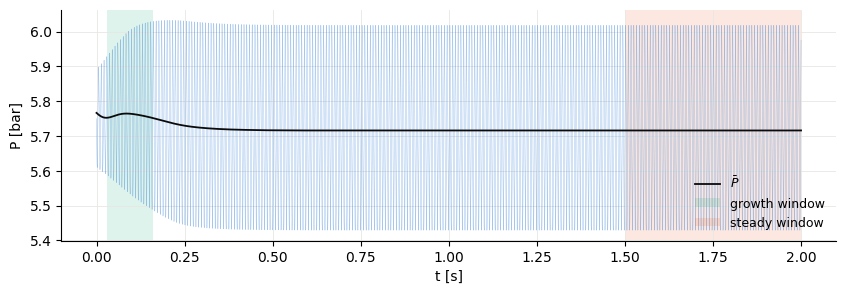

In [2]:
t, P, T, x = run_full(2.0)
fs = 1.0 / (t[1] - t[0])
bb, aa = butter(4, 12.0 / (fs / 2), 'low')
Pbar = filtfilt(bb, aa, P); Tbar = filtfilt(bb, aa, T)
Pp = P - Pbar

def harmonics(sig, tmin, tmax, nmax=6):
    """Amplitudes |c_n|, n = 0..nmax, of sig over whole cycles of P' inside [tmin, tmax]."""
    m = (t >= tmin) & (t <= tmax)
    tt, ref = t[m], Pp[m]
    s = np.sign(ref); up = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    tz = tt[up] - ref[up] * (tt[up + 1] - tt[up]) / (ref[up + 1] - ref[up])
    t0, tK, K = tz[0], tz[-1], len(tz) - 1
    w = 2 * np.pi * K / (tK - t0)
    mm = (t >= t0) & (t <= tK)
    tw, sw = t[mm], np.asarray(sig)[mm]
    psi = w * (tw - t0)
    dt = tw[1] - tw[0]
    integ = lambda y: (y.sum() - 0.5 * (y[0] + y[-1])) * dt
    c = [integ(sw) / (tK - t0)]
    for n in range(1, nmax + 1):
        c.append(2.0 * integ(sw * np.exp(-1j * n * psi)) / (tK - t0))
    return np.abs(np.array(c)), w, K

# the two windows: growth (envelope between 55 and 92 percent of its final value) and steady (last 0.5 s)
tenv = np.arange(0.03, 1.98, 0.01)
env = np.array([np.abs(Pp[(t >= tt0) & (t < tt0 + 0.01)]).max() for tt0 in tenv])
efin = env[-20:].mean()
ig = np.where((env > 0.55 * efin) & (env < 0.92 * efin) & (tenv < 1.0))[0]
W_GROW = (tenv[ig[0]], tenv[ig[-1]] + 0.01)
W_STEADY = (1.5, 2.0)
states = {}
for name, (a, b) in [('growth', W_GROW), ('steady', W_STEADY)]:
    cP, w, K = harmonics(Pp, a, b)
    m = (t >= a) & (t <= b)
    states[name] = dict(window=(a, b), Pbar=Pbar[m].mean(), Tbar=Tbar[m].mean(), delta=cP[1], w=w, K=K)
    print('%-7s window %.2f-%.2f s: %2d cycles, f = %.1f Hz, Pbar = %.4f bar, Tbar = %.1f K, delta = %.4f bar'
          % (name, a, b, K, w / 2 / np.pi, Pbar[m].mean() / 1e5, Tbar[m].mean(), cP[1] / 1e5))

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, P / 1e5, color=BLUE, lw=0.3, alpha=0.5)
ax.plot(t, Pbar / 1e5, color=INK, lw=1.3, label=r'$\bar P$')
for (a, b), col, lab in [(W_GROW, AQUA, 'growth window'), (W_STEADY, ORANGE, 'steady window')]:
    ax.axvspan(a, b, color=col, alpha=0.15, lw=0, label=lab)
ax.set_xlabel('t [s]'); ax.set_ylabel('P [bar]'); ax.legend(frameon=False, fontsize=9, loc='lower right')
for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
ax.grid(color=GRID, lw=0.6); plt.show()

## A. The harmonics of the valve term are not small

Take the state $(\bar P, \bar T, \delta)$ measured in each window, let the pressure swing be an ideal cosine, $P' = \delta\cos\psi$, and evaluate the valve term of the pressure equation over one cycle:

$$B(\psi) = \frac{C_f}{\bar V_{cv}}\Big[T_{in}\,F\!\left(P_{in} - \bar P - \delta\cos\psi\right) - \bar T\,F\!\left(\bar P - P_{out} + \delta\cos\psi\right)\Big]$$

and project it onto cosines: $B(\psi) = B_0 + \sum_n B_n\cos n\psi$ (the sine coefficients vanish because the valve has no memory — checked below). Writing $B_n = g_n\,\delta$ makes $g_1$ the feedback rate $g$ of the packet derivation, and puts every harmonic in the same units, 1/s.

In [3]:
PSI = np.linspace(0, 2 * np.pi, 4097)[:-1]

def valve_term(Pb, Tb, delta):
    Vc = geom(Pb)[1]
    Fi = reed_flow_vec(P_in - Pb - delta * np.cos(PSI))
    Fo = reed_flow_vec(Pb - P_out + delta * np.cos(PSI))
    return (Cf / Vc) * (T_in * Fi - Tb * Fo), Fi, Fo

def cos_coeffs(y, nmax=6):
    c = [y.mean()] + [2.0 * (y * np.cos(n * PSI)).mean() for n in range(1, nmax + 1)]
    s = [2.0 * (y * np.sin(n * PSI)).mean() for n in range(1, nmax + 1)]
    return np.array(c), np.array(s)

import pandas as pd
rows = []
for name, st in states.items():
    B, Fi, Fo = valve_term(st['Pbar'], st['Tbar'], st['delta'])
    c, s = cos_coeffs(B)
    st['g_n'] = c[1:] / st['delta']              # g_1 = g, g_2, g_3, ...
    st['B0'] = c[0]
    rows.append(dict(window=name, **{'g_%d [1/s]' % n: c[n] / st['delta'] for n in range(1, 6)},
                     **{'|g_%d/g_1|' % n: abs(c[n] / c[1]) for n in (2, 3, 4, 5)},
                     max_sine_coeff=np.abs(s).max() / abs(c[1])))
pd.DataFrame(rows).set_index('window').T.round(4)

window,growth,steady
g_1 [1/s],17.6615,5.1842
g_2 [1/s],-4.8533,2.4809
g_3 [1/s],-4.3443,-11.6669
g_4 [1/s],-1.1918,0.3055
g_5 [1/s],-0.7144,-2.8944
|g_2/g_1|,0.2748,0.4785
|g_3/g_1|,0.2460,2.2505
|g_4/g_1|,0.0675,0.0589
|g_5/g_1|,0.0405,0.5583
max_sine_coeff,0.0000,0.0000


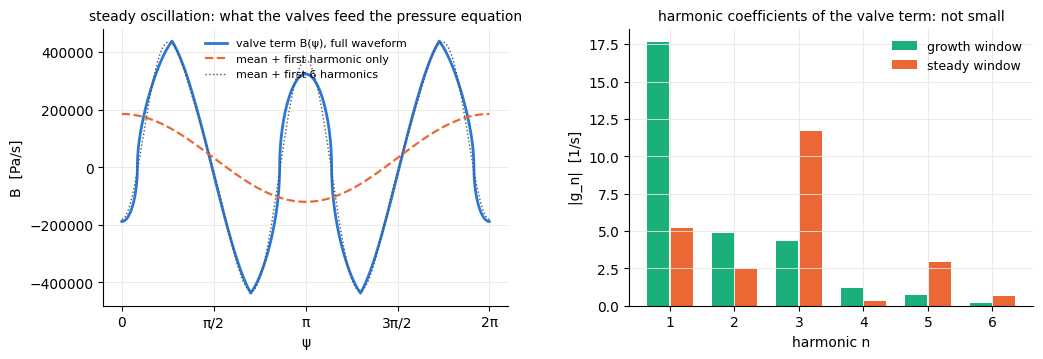

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6)); fig.subplots_adjust(wspace=0.3)
st = states['steady']
B, Fi, Fo = valve_term(st['Pbar'], st['Tbar'], st['delta'])
c, s = cos_coeffs(B)
ax = axs[0]
ax.plot(PSI / np.pi, B, color=BLUE, lw=2, label='valve term B(ψ), full waveform')
ax.plot(PSI / np.pi, c[0] + c[1] * np.cos(PSI), color=ORANGE, lw=1.6, ls='--', label='mean + first harmonic only')
ax.plot(PSI / np.pi, c[0] + sum(c[n] * np.cos(n * PSI) for n in range(1, 7)), color=INK2, lw=1, ls=':', label='mean + first 6 harmonics')
ax.set_xticks([0, 0.5, 1, 1.5, 2]); ax.set_xticklabels(['0', 'π/2', 'π', '3π/2', '2π'])
ax.set_xlabel('ψ'); ax.set_ylabel('B  [Pa/s]'); ax.set_title('steady oscillation: what the valves feed the pressure equation', fontsize=10)
ax.legend(frameon=False, fontsize=8)
ax = axs[1]
for name, col in [('growth', AQUA), ('steady', ORANGE)]:
    gn = states[name]['g_n']
    ax.bar(np.arange(1, 7) + (0.18 if name == 'steady' else -0.18), np.abs(gn), width=0.34, color=col, label=name + ' window')
ax.set_xlabel('harmonic n'); ax.set_ylabel('|g_n|  [1/s]'); ax.set_title('harmonic coefficients of the valve term: not small', fontsize=10)
ax.legend(frameon=False, fontsize=9)
for a in axs:
    for sp in ['top', 'right']: a.spines[sp].set_visible(False)
    a.grid(color=GRID, lw=0.6)
plt.show()

## B. What the resonator does with each harmonic

Project the fast equations $\dot P' = -(k_{cv}/A)\dot x' + B(\psi)$ and $m\ddot x' + b\dot x' + k_{pass}x' = AP'$ onto $e^{-in\psi}$ with the ansatz $P' \ni \mathrm{Re}[\hat p_n e^{in\psi}]$, $x' \ni \mathrm{Re}[\hat x_n e^{in\psi}]$. For $n = 1$ the piston bracket $k_{cv} + k_{pass} - m\omega_0^2$ vanishes, no algebraic solution exists, and the slow derivative must carry the balance: that is the envelope equation, $\dot\delta = \lambda\delta$ with $\lambda = -b/2m + g L/2$, $L = k_{cv}/(k_{cv}+k_{pass})$. For $n \ge 2$ the bracket is $-m\omega_0^2(n^2 - 1) \ne 0$ and the balance closes algebraically:

$$\hat p_n = \frac{B_n}{i n\omega_0}\left(1 + \frac{L}{n^2-1}\right) \qquad\Longrightarrow\qquad \frac{\lvert\hat p_n\rvert}{\delta} = \frac{\lvert g_n\rvert}{n\,\omega_0}\left(1 + \frac{L}{n^2-1}\right)$$

a bounded ripple, present from the first cycle and never growing. The fair comparison is between this ripple and what the first harmonic does *per cycle*, $2\pi\lambda/\omega_0$: both are of order $g/\omega_0 \approx 10^{-2}$. The difference is that the first harmonic's effect compounds over hundreds of cycles ($Q \approx 240$) and the ripple does not.

**A second source of harmonics, not from the valves.** The packet derivation also linearizes the two gas springs ([10] and the passive adiabat [5]). The sealed relation $P = \bar P\,(\bar V_{cv}/V)^{\gamma_E}$ is curved: with $x' = a\cos\psi$ its expansion to second order carries a $\cos^2\psi = \tfrac12(1 + \cos 2\psi)$ term. Writing it per unit $\delta$ and adding the passive spring's curvature (which reaches the CV pressure through the piston's slaved $2\omega_0$ motion, bracket $-3m\omega_0^2$ again):

$$\frac{\lvert\hat p_2\rvert_{\text{springs}}}{\delta} = r_{cv} + \frac{L}{3}\left(r_{cv} - r_{p}\right), \qquad r_{cv} = \frac{\gamma_E + 1}{4\gamma_E}\frac{\delta}{\bar P}, \qquad r_{p} = \frac{\gamma(\gamma+1)}{4\gamma_E^2}\left(\frac{\bar V_{cv}}{\bar V_{pass}}\right)^2\frac{\delta}{\bar P}$$

This is in phase with $\cos 2\psi$, while the valve contribution carries the factor $1/i$ — a quarter cycle apart — so the two add in quadrature. At $\delta/\bar P \approx 5$ percent the spring term is about 2.5 percent of $\delta$: larger than anything the valves produce, still bounded, still proportional to $\delta^2$, and still absent from the envelope equation at first order. The spring's $\cos 3\psi$ term is of order $(\delta/\bar P)^2 \approx 0.05$ percent and is ignored.

In [5]:
rows = []
for name, st in states.items():
    Vp, Vc, kcv, kp, w0 = geom(st['Pbar'])
    L = kcv / (kcv + kp)
    gn = st['g_n']
    lam = -b_gas / (2 * m_gas) + 0.5 * gn[0] * L
    st['w0'], st['L'], st['lam'] = w0, L, lam
    st['ripple_pred'] = np.array([abs(gn[n - 1]) / (n * w0) * (1 + L / (n**2 - 1)) for n in range(2, 6)])
    rows.append(dict(window=name, omega0=w0, L=L, g=gn[0], lam=lam,
                     growth_per_cycle=2 * np.pi * lam / w0,
                     **{'ripple_%d = |p_%d|/delta' % (n, n): st['ripple_pred'][n - 2] for n in range(2, 6)}))
pd.DataFrame(rows).set_index('window').T.round(5)

window,growth,steady
omega0,807.03500,806.13899
L,0.66202,0.66564
g,17.66150,5.18417
lam,4.17945,0.05872
growth_per_cycle,0.03254,0.00046
ripple_2 = |p_2|/delta,0.00367,0.00188
ripple_3 = |p_3|/delta,0.00194,0.00523
ripple_4 = |p_4|/delta,0.00039,0.00010
ripple_5 = |p_5|/delta,0.00018,0.00074


## C. Measured in the full simulation

Now no ansatz at all. From the simulated trace: the harmonics of the two flows $F_{in}(t)$, $F_{out}(t)$ (large), of the valve term $B(t)$ built from them (large, and it should reproduce the $g_n$ of part A), and of the pressure fluctuation $P'(t)$ itself (small). The measured $\lvert p_n\rvert/\delta$ is compared with the ripple formulas of part B — the valve term evaluated with the *measured* $g_n$, and for $n = 2$ the gas-spring curvature added in quadrature.

The growth window is the stronger test: the amplitude is growing there by a percent per cycle, and if the second harmonic contributed to that growth it would show up as a harmonic content that changes with time. It does not. (The growth window holds only 16 cycles and the amplitude changes by half across it, so its numbers are rougher — factor-of-1.5 agreement there, a few percent in the steady window.)

In [6]:
Fin_t = reed_flow_vec(P_in - P); Fout_t = reed_flow_vec(P - P_out)
Vc_t = V0_cv + x * A_neck
B_t = (Cf / Vc_t) * (T_in * Fin_t - T * Fout_t)
rows = []
for name, st in states.items():
    a, b = st['window']
    cP, w, K = harmonics(Pp, a, b); cI, _, _ = harmonics(Fin_t, a, b); cO, _, _ = harmonics(Fout_t, a, b); cB, _, _ = harmonics(B_t, a, b)
    gn_meas = cB[1:] / cP[1]
    st['gn_meas'] = gn_meas
    st['ripple_meas'] = cP[2:6] / cP[1]
    st['ripple_valve'] = np.array([gn_meas[n - 1] / (n * st['w0']) * (1 + st['L'] / (n**2 - 1)) for n in range(2, 6)])
    Vp, Vc, kcv, kp, w0 = geom(st['Pbar']); L = st['L']; r = cP[1] / st['Pbar']
    r_cv = (gamma_E + 1) / (4 * gamma_E) * r
    r_p = gamma * (gamma + 1) / (4 * gamma_E**2) * (Vc / Vp)**2 * r
    st['ripple_spring2'] = r_cv + (L / 3) * (r_cv - r_p)
    st['ripple_total'] = st['ripple_valve'].copy()
    st['ripple_total'][0] = np.hypot(st['ripple_valve'][0], st['ripple_spring2'])
    for n in range(2, 6):
        rows.append(dict(window=name, n=n,
                         inlet_flow=cI[n] / cI[1], outlet_flow=cO[n] / cO[1], valve_term=cB[n] / cB[1],
                         g_n_measured=gn_meas[n - 1], g_n_partA=abs(st['g_n'][n - 1]),
                         pressure_measured=cP[n] / cP[1], pred_valves=st['ripple_valve'][n - 2],
                         pred_springs=(st['ripple_spring2'] if n == 2 else 0.0), pred_total=st['ripple_total'][n - 2]))
df = pd.DataFrame(rows).set_index(['window', 'n'])
df.columns = ['|F_in,n / F_in,1|', '|F_out,n / F_out,1|', '|B_n / B_1|', 'g_n measured [1/s]', 'g_n part A [1/s]',
              '|p_n|/delta measured', 'predicted: valves', 'predicted: spring curvature', 'predicted: total']
df.round(4)

|F_in,n / F_in,1|  |F_out,n / F_out,1|  |B_n / B_1|  \
window n                                                        
growth 2             2.0966               0.2270       0.3881   
       3             0.8838               0.2092       0.4024   
       4             0.3545               0.0607       0.1496   
       5             0.2937               0.0155       0.0936   
steady 2             2.3653               4.5357       0.2374   
       3             1.9784               2.9831       2.3426   
       4             0.5782               0.6856       0.1625   
       5             0.5008               0.8274       0.6266   

          g_n measured [1/s]  g_n part A [1/s]  |p_n|/delta measured  \
window n                                                               
growth 2              5.8215            4.8533                0.0182   
       3              6.0359            4.3443                0.0017   
       4              2.2441            1.1918                0.0009   
       5              1.4047            0.7144                0.0007   
steady 2              1.1937            2.4809                0.0259   
       3             11.7806           11.6669                0.0053   
       4              0.8174            0.3055                0.0003   
       5              3.1509            2.8944                0.0008   

          predicted: valves  predicted: spring curvature  predicted: total  
window n                                                                    
growth 2             0.0044                       0.0202            0.0206  
       3             0.0027                       0.0000            0.0027  
       4             0.0007                       0.0000            0.0007  
       5             0.0004                       0.0000            0.0004  
steady 2             0.0009                       0.0259            0.0259  
       3             0.0053                       0.0000            0.0053  
       4             0.0003                       0.0000            0.0003  
       5             0.0008                       0.0000            0.0008

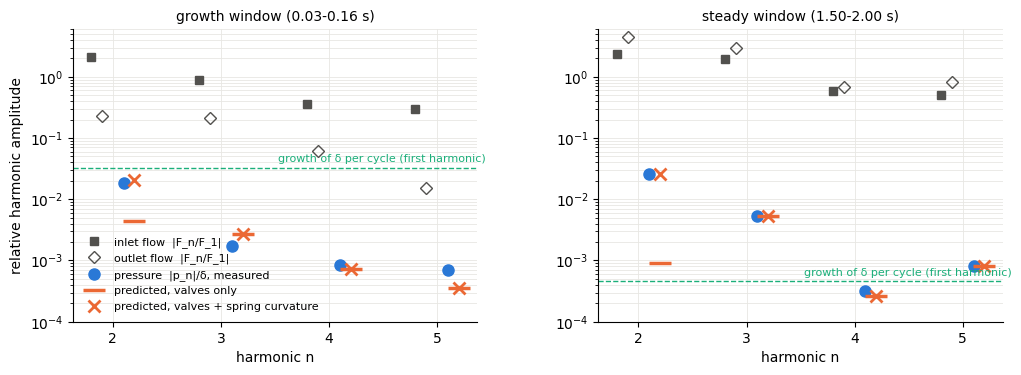

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8)); fig.subplots_adjust(wspace=0.3)
ns = np.arange(2, 6)
for ax, name in zip(axs, ['growth', 'steady']):
    st = states[name]; a, b = st['window']
    cP, _, _ = harmonics(Pp, a, b); cI, _, _ = harmonics(Fin_t, a, b); cO, _, _ = harmonics(Fout_t, a, b)
    ax.semilogy(ns - 0.2, cI[2:6] / cI[1], 's', color=INK2, label='inlet flow  |F_n/F_1|')
    ax.semilogy(ns - 0.1, cO[2:6] / cO[1], 'D', color=INK2, mfc='none', label='outlet flow  |F_n/F_1|')
    ax.semilogy(ns + 0.1, st['ripple_meas'], 'o', color=BLUE, ms=8, label='pressure  |p_n|/δ, measured')
    ax.semilogy(ns + 0.2, st['ripple_valve'], '_', color=ORANGE, ms=16, mew=2.5, label='predicted, valves only')
    ax.semilogy(ns + 0.2, st['ripple_total'], 'x', color=ORANGE, ms=9, mew=2, label='predicted, valves + spring curvature')
    if st['lam'] > 0:
        ax.axhline(2 * np.pi * st['lam'] / st['w0'], color=AQUA, ls='--', lw=1)
        ax.text(5.45, 2 * np.pi * st['lam'] / st['w0'] * 1.25, 'growth of δ per cycle (first harmonic)', color=AQUA, fontsize=8, ha='right')
    ax.set_xticks(ns); ax.set_xlabel('harmonic n'); ax.set_ylim(1e-4, 6)
    ax.set_title('%s window (%.2f-%.2f s)' % (name, a, b), fontsize=10)
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6, which='both')
axs[0].set_ylabel('relative harmonic amplitude'); axs[0].legend(frameon=False, fontsize=8, loc='lower left')
plt.show()

### Where the pressure's second harmonic comes from: a sealed run

Shut the valves ($\dot m_{max} = 0$), start the resonator at the steady-oscillation amplitude, and measure the harmonics of the free oscillation. Nothing but the gas springs is left, so whatever $\cos 2\psi$ survives is the springs' curvature.

In [8]:
m_save, m_max = m_max, 0.0
st = states['steady']
Pb, Tb = st['Pbar'], st['Tbar']
Vp, Vc, kcv, kp, w0 = geom(Pb)
a_amp = st['delta'] * A_neck / kcv
x_eq = (V0_pass - Vp) / A_neck                 # piston position at which P_pass = Pbar
Mg = Pb * Vc / (R * Tb)
x_start = x_eq - a_amp
Vc_s = V0_cv + x_start * A_neck
P_s = Pb * (Vc / Vc_s)**gamma_E                # sealed compression from the mean state
E_s = cv * Mg * P_s * Vc_s / (Mg * R)
tes = np.arange(0.0, 0.3, 1.0 / fs)
sols = solve_ivp(full_ode, (0.0, 0.3), [x_start, 0.0, Mg, E_s], t_eval=tes, method='RK45', rtol=1e-10, atol=1e-12)
m_max = m_save
xs, vs, Ms, Es = sols.y
Ps = Ms * R * (Es / (cv * Ms)) / (V0_cv + xs * A_neck)
Pps = Ps - Ps.mean()
mask = (tes > 0.05) & (tes < 0.25)
tt, ref = tes[mask], Pps[mask]
sg = np.sign(ref); up = np.where((sg[:-1] < 0) & (sg[1:] >= 0))[0]
tz = tt[up] - ref[up] * (tt[up + 1] - tt[up]) / (ref[up + 1] - ref[up]); t0, tK, K = tz[0], tz[-1], len(tz) - 1
w = 2 * np.pi * K / (tK - t0); mm = (tes >= t0) & (tes <= tK); psi = w * (tes[mm] - t0); dt = 1.0 / fs
integ = lambda y: (y.sum() - 0.5 * (y[0] + y[-1])) * dt
cs = np.abs(np.array([integ(Pps[mm]) / (tK - t0)] + [2 * integ(Pps[mm] * np.exp(-1j * n * psi)) / (tK - t0) for n in range(1, 5)]))
r = cs[1] / Pb; L = kcv / (kcv + kp)
r_cv = (gamma_E + 1) / (4 * gamma_E) * r; r_p = gamma * (gamma + 1) / (4 * gamma_E**2) * (Vc / Vp)**2 * r
print('sealed resonator, delta = %.4f bar:   |p_2|/delta measured = %.4f   formula = %.4f   (|p_3|/delta = %.5f)'
      % (cs[1] / 1e5, cs[2] / cs[1], r_cv + (L / 3) * (r_cv - r_p), cs[3] / cs[1]))

sealed resonator, delta = 0.2322 bar:   |p_2|/delta measured = 0.0219   formula = 0.0204   (|p_3|/delta = 0.00073)


## D. Same strength, two harmonics: growth versus ripple

The fast system of the packet derivation with the family-1 springs, damping switched off, and one forcing term added to $\dot P'$: either $g P'$ (the first harmonic, proportional to the state) or $g\,\delta_0\cos 2\omega_0 t$ (a second harmonic of the same strength). Exact numerical solutions of the linear equations, no averaging anywhere.

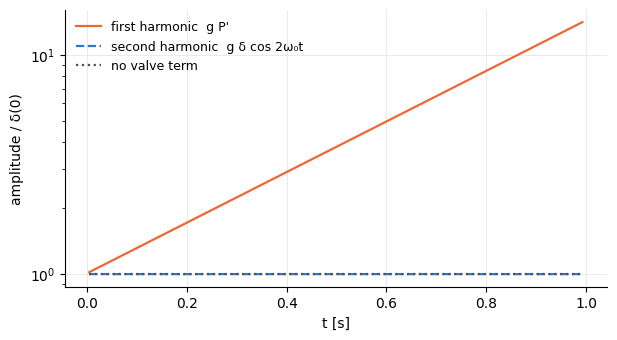

first harmonic : amplitude x14.1 in 1 s   (e^(gL/2 t) predicts x14.2)
second harmonic: amplitude x1.000, ripple 0.76% of δ   (formula g/(2ω0)(1+L/3) = 0.61%)


In [9]:
Vp, Vc, kcv, kp, w0 = geom(P0)
g_toy, d0 = 8.0, 1.0e4
def fast_rhs(t_, y, mode):
    Pf, xf, vf = y
    S = g_toy * Pf if mode == 'first' else (g_toy * d0 * np.cos(2 * w0 * t_) if mode == 'second' else 0.0)
    return [-(kcv / A_neck) * vf + S, vf, (A_neck * Pf - kp * xf) / m_gas]
y0 = [d0, -d0 * A_neck / kcv, 0.0]
Tc = 2 * np.pi / w0; t_end = 1.0
te = np.linspace(0, t_end, 200001)
runs = {k: solve_ivp(fast_rhs, (0, t_end), y0, t_eval=te, args=(k,), rtol=1e-10, atol=1e-8).y[0] for k in ['first', 'second', 'none']}
def per_cycle_amp(sig):
    n = int(t_end / Tc); return np.array([(i + 0.5) * Tc for i in range(n)]), np.array([np.abs(sig[(te >= i * Tc) & (te < (i + 1) * Tc)]).max() for i in range(n)])
L0 = kcv / (kcv + kp)
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, col, ls, lab in [('first', ORANGE, '-', "first harmonic  g P'"), ('second', BLUE, '--', 'second harmonic  g δ cos 2ω₀t'), ('none', INK2, ':', 'no valve term')]:
    tc, amp = per_cycle_amp(runs[k]); ax.semilogy(tc, amp / d0, color=col, ls=ls, lw=1.6, label=lab)
ax.set_xlabel('t [s]'); ax.set_ylabel('amplitude / δ(0)'); ax.legend(frameon=False, fontsize=9)
for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
ax.grid(color=GRID, lw=0.6); plt.show()
ripple = np.abs(runs['second'] - runs['none']).max() / d0
print('first harmonic : amplitude x%.1f in 1 s   (e^(gL/2 t) predicts x%.1f)' % (np.abs(runs['first'][-2000:]).max() / d0, np.exp(0.5 * g_toy * L0 * t_end)))
print('second harmonic: amplitude x%.3f, ripple %.2f%% of δ   (formula g/(2ω0)(1+L/3) = %.2f%%)'
      % (np.abs(runs['second'][-2000:]).max() / d0, 100 * ripple, 100 * g_toy / (2 * w0) * (1 + L0 / 3)))

## Summary

The valves' waveforms are strongly non-sinusoidal: in the flows and in the valve term of the pressure equation, the second and third harmonics are tens of percent of the first (part A, and measured in part C). None of that reaches the pressure oscillation at a level that matters: the resonator turns the $n$-th harmonic of the forcing into a pressure ripple of relative size $\lvert g_n\rvert/(n\omega_0)\,(1 + L/(n^2-1))$, under one percent here, and the measured harmonic content of $P'$ for $n \ge 3$ matches that formula in both windows (part C). The one harmonic that is visibly larger, $\cos 2\psi$ at about 2.5 percent of $\delta$, is not the valves' doing: it is the curvature of the gas springs, $\propto\delta^2/\bar P$, reproduced by the formula of part B and by a sealed run with the valves shut. The ripple is the same during growth and on the steady oscillation — it is a fixed decoration on the waveform, not a contribution to its envelope — while the first harmonic, of the same per-cycle size, compounds into the observed growth (part D). This is the quantitative content of "dropping the higher harmonics" in the packet derivation: dropped from the envelope and mean equations, where their projection is exactly zero, and left out of the waveform at a cost of under one percent.